In [34]:
import pandas as pd

In [35]:
import seaborn as sns

In [36]:
df=pd.read_csv('iris.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [37]:
x=df[['sepal_length','sepal_width','petal_length','petal_width']]
x

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [38]:
y=df[['species']]
y

,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa
...,...
145,virginica
146,virginica
147,virginica
148,virginica


In [39]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaled_data=pd.DataFrame(scaler.fit_transform(x))

<Axes: >

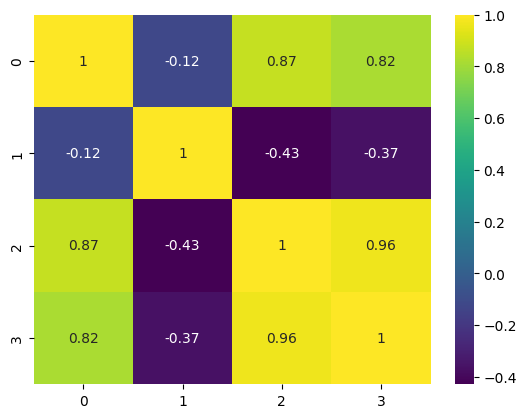

In [40]:
sns.heatmap(scaled_data.corr(),cmap='viridis',annot=True)


In [41]:
from sklearn.decomposition import PCA
pca=PCA(n_components=4)
pca.fit(scaled_data)
x_pca=pca.transform (scaled_data)
x=pd.DataFrame(x_pca,columns=['PC1','PC2','PC3','PC4'])
x_pca
x.head()

,PC1,PC2,PC3,PC4
0,-2.264703,0.480027,0.127706,-0.024168
1,-2.080961,-0.674134,0.234609,-0.103007
2,-2.364229,-0.341908,-0.044201,-0.028377
3,-2.299384,-0.597395,-0.091290,0.065956
4,-2.389842,0.646835,-0.015738,0.035923


<Axes: >

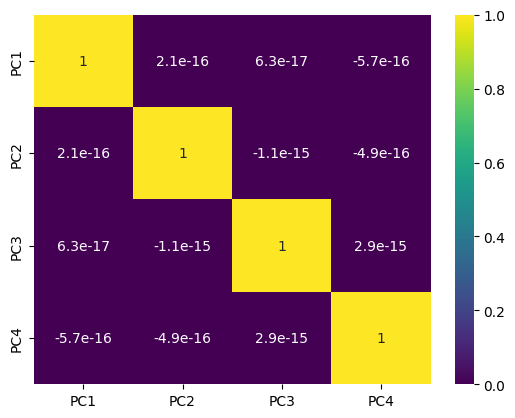

In [42]:
sns.heatmap(x.corr(), cmap='viridis',annot=True)

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

x_train,x_test,y_train,y_test=train_test_split(
x_pca,y,test_size=0.2,random_state=3)
dtc=DecisionTreeClassifier()
dtc.fit(x_train,y_train)
y_pred = dtc.predict(x_test)
print(y_pred)

['setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'virginica' 'versicolor'
 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'versicolor' 'virginica' 'virginica'
 'setosa' 'virginica' 'virginica' 'virginica' 'versicolor' 'setosa'
 'virginica' 'virginica' 'versicolor' 'versicolor' 'versicolor']


In [44]:
y_pred=dtc.predict(x_test)
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

1.0